# 02 · Manifold — topology test → scFates fit → root → pseudotime

Score the three developmental modules, graph-smooth them for geography, then **test branching honestly**: fit a PPT *tree* and count branch nodes across a parameter sweep, render the edges on the embedding, and compare to a *curve*. A curve is committed only if the manifold is truly non-branching. Root from the signatures' developmental order (Gast/pSom origin; Crest is late).

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
%matplotlib inline
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth,'data')
pth_out = os.path.join(pth_data,'cancer', 'vertebrate', 'CCCA', 'claude',cat,name)
pth_fig = os.path.join(pth,'figures', 'mesencontext', 'claude',cat,name)
pth_cb  = os.path.join(pth_fig,'colorbars'); pth_feat = os.path.join(pth_data,'features','biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out,'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
u,s,vt = np.linalg.svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

whole malignant manifold: 3936 cells
UMAP aspect ratio (major/minor std): 1.21


### Score developmental modules + graph-smooth for geography
`score_genes` with the union control pool. Smoothed (kNN-averaged) scores are used to read geography and correlations; **raw** per-cell scores are shown in the 03 deliverable UMAPs.

In [4]:
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

Gast: 76/81 genes present
pSom: 91/98 genes present
Crest: 104/104 genes present


In [5]:
print('module means (raw):', {l: round(float(adata.obs[l].mean()),3) for l in ['Gast','pSom','Crest']})
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
adata.obs['cyc'] = pd.to_numeric(adata.obs['g1s_score'],errors='coerce').fillna(0).combine(
                   pd.to_numeric(adata.obs['g2m_score'],errors='coerce').fillna(0), max)
print('proliferation confound (cyc vs smoothed signatures):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    print(f'  cyc vs {s}: r = {np.corrcoef(adata.obs["cyc"],adata.obs[s])[0,1]:+.2f}')
print('-> Gast axis is NOT proliferation-driven (cyc vs Gast_sm ~ -0.16); keep whole manifold.')

module means (raw): {'Gast': 0.029, 'pSom': 0.077, 'Crest': -0.02}
smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = +0.44
  Crest_sm vs Gast_sm: r = +0.06
  Crest_sm vs pSom_sm: r = -0.68
proliferation confound (cyc vs smoothed signatures):
  cyc vs Gast_sm: r = -0.16
  cyc vs pSom_sm: r = +0.48
  cyc vs Crest_sm: r = -0.35
-> Gast axis is NOT proliferation-driven (cyc vs Gast_sm ~ -0.16); keep whole manifold.


### Honest branching test — PPT tree branch-node sweep
A genuine bifurcation yields ~1 stable fork; noise over-segments into many forks that grow with node count. Fit the tree across (Nodes, lambda) and count.

In [6]:
def topo(ad):
    B = np.asarray(ad.uns['graph']['B']); deg = (B>0).sum(0)
    return int((deg==1).sum()), int((deg>=3).sum())
print('PPT tree fork counts across the parameter sweep:')
for Nodes in [30,50,80]:
    for lam in [10,30]:
        with contextlib.redirect_stdout(io.StringIO()):
            scf.tl.tree(adata, method='ppt', Nodes=Nodes, ppt_lambda=lam, ppt_sigma=0.5,
                        use_rep='X_umap', seed=SEED, plot=False)
        t,f = topo(adata); print(f'  Nodes={Nodes} lambda={lam}: tips={t} forks={f}')
print('-> forks scale with node count (7->13); no stable single bifurcation = spurious over-segmentation.')

PPT tree fork counts across the parameter sweep:
  Nodes=30 lambda=10: tips=8 forks=6
  Nodes=30 lambda=30: tips=5 forks=3
  Nodes=50 lambda=10: tips=9 forks=6
  Nodes=50 lambda=30: tips=10 forks=7
  Nodes=80 lambda=10: tips=15 forks=13
  Nodes=80 lambda=30: tips=14 forks=12
-> forks scale with node count (7->13); no stable single bifurcation = spurious over-segmentation.


### Render the tree edges on the embedding — visual confirmation
The spider-web of branches over one continuous cloud is the *tree-on-a-strip* signature, not a Y.

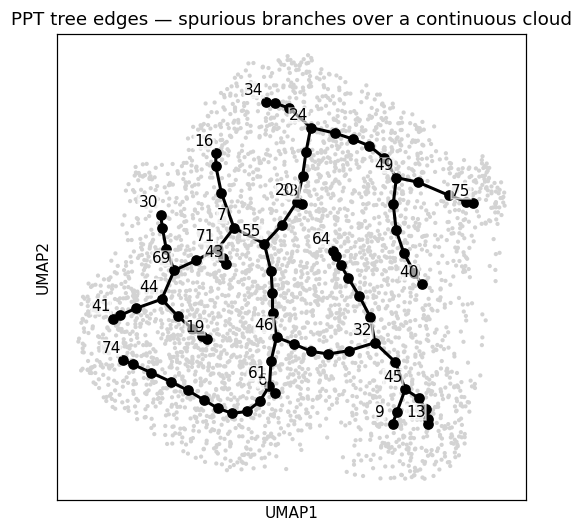

In [7]:
fig, ax = plt.subplots(figsize=(5.5,5.5))
scf.pl.graph(adata, basis='umap', show=False, ax=ax)
ax.set_title('PPT tree edges — spurious branches over a continuous cloud')

### Fit the curve (non-branching) + fold-free check
Fold self-approach ratio = min Euclidean distance between graph-distant node pairs / median edge length; >1 means the curve does not fold back through the cloud.

In [8]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    return dmin/med, int(((B>0).sum(0)==1).sum()), int(((B>0).sum(0)>=3).sum())
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.70 (>1 = fold-free)


### Root from developmental order + pseudotime
Both tips are Gast/pSom-high vs Crest-low; root at the tip maximising (Gast+pSom−Crest). Crest is developmentally late, so it must sit at the terminus, not the root.

In [9]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed scores):')
for s in ['Gast_sm','pSom_sm','Crest_sm','cyc']:
    rho,p = spearmanr(t, adata.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=+0.0344 pSom=+0.0823 Crest=-0.0283
tip 2: Gast=+0.0251 pSom=+0.0785 Crest=-0.0155
derived root = tip 0 (Gast/pSom-high, Crest-low developmental origin)
gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho=-0.407 p=5.2e-157
  pSom_sm: rho=-0.181 p=1.8e-30
  Crest_sm: rho=+0.470 p=5.7e-216
  cyc: rho=+0.267 p=2.1e-65


### Oriented linear layout
Rotate the UMAP so pseudotime runs left→right (house linear trajectory layout); this `X_umap_lin` is used for every downstream deliverable panel. The rotation is a rigid transform of the *same* embedding — no re-embedding of the linear compartment.

In [10]:
xy = adata.obsm['X_umap'].copy(); c = xy - xy.mean(0)
w = np.linalg.lstsq(c, t - t.mean(), rcond=None)[0]; w = w/np.linalg.norm(w)
Rot = np.array([[w[0], w[1]], [-w[1], w[0]]]); xyr = c @ Rot.T
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0: xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0.5, f'pseudotime not aligned left->right (corr={r:+.2f})'
adata.obsm['X_umap_lin'] = xyr
print(f'orientation: rigid rotation; corr(x_lin, pseudotime) = {r:+.2f}')

orientation: rigid rotation; corr(x_lin, pseudotime) = +0.93


### Render fitted curve edges on the oriented layout — fold check (visual)

single fold-free arc: Gast/pSom pole -> Crest pole


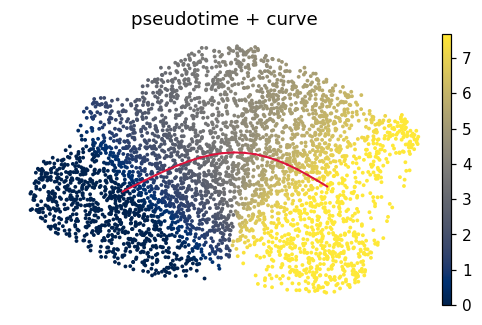

In [11]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
F = adata.uns['graph']['F'].T; c0 = adata.obsm['X_umap'].mean(0)
Fr = (F - c0) @ Rot.T
if float(np.corrcoef(((adata.obsm['X_umap']-c0)@Rot.T)[:,0], t)[0,1]) < 0: Fr[:,0] = -Fr[:,0]
fig, ax = plt.subplots(figsize=(5.5,3.2))
sc.pl.umap(plot, color='t', cmap='cividis', size=25, frameon=False, show=False, ax=ax, title='pseudotime + curve')
Bc = np.asarray(adata.uns['graph']['B']); ii,jj = np.where(np.triu(Bc>0))
for a,b in zip(ii,jj): ax.plot(Fr[[a,b],0], Fr[[a,b],1], '-', color='crimson', lw=1.3, zorder=5)
print('single fold-free arc: Gast/pSom pole -> Crest pole')

In [12]:
# sanitize non-serializable ElPiGraph uns entry before writing
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out,'manifold.h5ad'))
print('saved manifold.h5ad', adata.shape)

saved manifold.h5ad (3936, 22675)


### Deliverable — `manifold.pdf`
House `(3.5,1.5)` linear layout, pseudotime left→right.

saved manifold.pdf


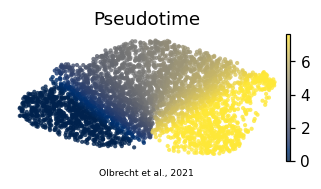

In [13]:
xl = adata.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Olbrecht et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.pdf')